Simple Model
Training Error: 5.67
Testing Error: 14.12

Complex Model
Training Error: 7.12
Testing Error: 62.39



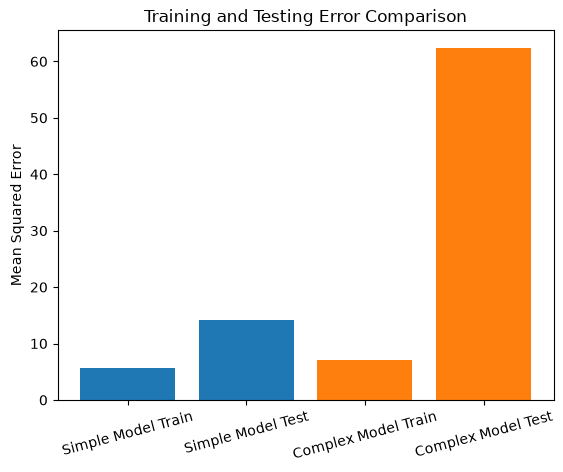

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# Generate sample data
np.random.seed(7)
X = np.linspace(0, 10, 30).reshape(-1, 1)
y = 2 * X.ravel() + 3 * np.sin(X.ravel()) + np.random.normal(0, 2, 30)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

models = {
    "Simple Model": 1,
    "Complex Model": 15
}

for name, degree in models.items():
    model = make_pipeline(
        PolynomialFeatures(degree),
        LinearRegression()
    )
    model.fit(X_train, y_train)

    train_error = mean_squared_error(
        y_train, model.predict(X_train)
    )
    test_error = mean_squared_error(
        y_test, model.predict(X_test)
    )

    print(name)
    print("Training Error:", round(train_error, 2))
    print("Testing Error:", round(test_error, 2))
    print()

    plt.bar(
        [name + " Train", name + " Test"],
        [train_error, test_error]
    )

plt.title("Training and Testing Error Comparison")
plt.ylabel("Mean Squared Error")
plt.xticks(rotation=15)
plt.show()